# 04. Model B: sieć probabilistyczna (Flipout)

Cel: wytrenować model B, czyli **tę samą architekturę co model A, ale z warstwami Flipout** (`probabilistic=True`),
dobrać jego własne hiperparametry **na zbiorze walidacyjnym** i porównać go z modelem A.
Architekturę, learning rate, dropout i wagi klas przejmujemy z modelu A bez zmian (`results/config_A.json`),
żeby różnica między modelami wynikała z warstw probabilistycznych, a nie z innej konfiguracji.
Zbioru testowego tu również **nie używamy**.

1. Architektura
2. Pierwszy trening
3. Ocena na walidacji i porównanie z modelem A
4. Dobór hiperparametrów
5. Wybrana konfiguracja i porównanie z modelem A
6. Niepewność aleatoryczna i epistemiczna
7. Wnioski

Każdy trening jest logowany w `runs/<data>_<godzina>_<nazwa>/` (konfiguracja, historia, wagi, metryki, predykcje), a zbiorcza tabela jest w `runs/index.csv`.
Ponowne uruchomienie notebooka wczytuje gotowe przebiegi zamiast trenować od nowa.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from src.data import CLASSES, ROOT
from src.evaluate import metrics, predictions_frame, reliability
from src.models import DEFAULT_CONFIG, build_model, predict_samples
from src.preprocessing import load_dataset
from src.runs import list_runs, run_or_load

sns.set_theme(style="whitegrid")
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

data = load_dataset()
y_train, y_val = data["train"]["y"], data["val"]["y"]

/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1795554102.760320    4001 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795554108.102871    4001 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Konfiguracja wybrana w modelu A

Wczytujemy `results/config_A.json` zapisany na końcu notebooka 03. JSON zamienia krotki na listy (np. `filters`),
więc przy porównywaniu z `DEFAULT_CONFIG` przywracamy krotki. Do `run_or_load` przekazujemy tylko różnice względem domyślnej konfiguracji.

In [2]:
saved_A = json.loads((RESULTS / "config_A.json").read_text())
config_A = saved_A["config"]


def to_changes(config):
    """Różnice względem DEFAULT_CONFIG (listy z JSON-a wracają do krotek)."""
    changes = {}
    for key, value in config.items():
        value = tuple(value) if isinstance(value, list) else value
        if value != DEFAULT_CONFIG.get(key):
            changes[key] = value
    return changes


changes_A = to_changes(config_A)
print("Zmiany względem konfiguracji domyślnej:", changes_A or "brak (wybrana = domyślna)")

# Model A do porównania: ten sam przebieg, który wybrał notebook 03 (identyczny przebieg jest tylko wczytywany)
run_A = run_or_load("A_wybrany", data, changes_A)
print(f"Model A: {run_A.run_id}")
pd.Series(config_A, name="konfiguracja przejęta z modelu A").to_frame()

Zmiany względem konfiguracji domyślnej: brak (wybrana = domyślna)


E0000 00:00:1795554136.296153    4001 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model A: 2026-11-22_22-10-32_A_bazowy


,konfiguracja przejęta z modelu A
filters,"[32, 64, 64, 128]"
kernel_size,7
dense_units,64
dropout,0.3
learning_rate,0.001
batch_size,64
epochs,60
patience,8
class_weight_power,1.0
kl_scale,1.0


## 1. Architektura

Taka sama jak w modelu A: cztery bloki **[konwolucja 1D → BatchNorm → ReLU → MaxPool]**, uśrednienie po czasie,
warstwa gęsta i warstwa wyjściowa z 5 logitami. W modelu B konwolucje i warstwy gęste są zastąpione przez
`Convolution1DFlipout` i `DenseFlipout`. Każda waga ma rozkład (średnia i odchylenie), a przy każdym przebiegu w przód
losujemy z niego nowe wagi. Do straty dochodzi składnik **KL** (odległość rozkładu wag od rozkładu a priori), ważony przez `kl_scale`.
Predykcja to średnia z `mc_samples` przebiegów (domyślnie 50).

In [3]:
model_B_arch = build_model(probabilistic=True, n_train=len(y_train))
model_B_arch.summary()

/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scale = add_variable_fn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than on

Model: "model_B"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 1000, 12)]        0         
                                                                 
 conv1d_flipout (Conv1DFlip  (None, 1000, 32)          5408      
 out)                                                            
                                                                 
 batch_normalization_4 (Bat  (None, 1000, 32)          128       
 chNormalization)                                                
                                                                 
 re_lu_4 (ReLU)              (None, 1000, 32)          0         
                                                                 
 max_pooling1d_4 (MaxPoolin  (None, 500, 32)           0         
 g1D)                                                            
                                                           

In [4]:
pd.Series({"model A": build_model().count_params(), "model B": model_B_arch.count_params()},
          name="parametrów (konfiguracja domyślna)").to_frame()

,parametrów (konfiguracja domyślna)
model A,113061
model B,224613


## 2. Pierwszy trening

Konfiguracja przejęta z modelu A, `kl_scale = 1`, early stopping na stracie walidacyjnej (cierpliwość 8 epok).

In [5]:
def run(name, **changes):
    return run_or_load(f"B_{name}", data, {**changes_A, **changes}, probabilistic=True)


base_B = run("bazowy")
model_B = base_B.model
print(f"Przebieg: {base_B.run_id}")
print(f"Epok: {base_B.metrics['epochs']}, czas: {base_B.metrics['seconds'] / 60:.1f} min")

/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scal

Przebieg: 2026-11-24_22-13-06_B_bazowy
Epok: 16, czas: 9.5 min


In [6]:
# Zabezpieczenie: model B z Flipout ma więcej parametrów niż A (średnia i odchylenie dla każdej wagi)
assert base_B.metrics["parameters"] > run_A.metrics["parameters"], (
    "Przebieg B_bazowy ma tyle samo parametrów co model A, więc run_or_load zbudował model deterministyczny. "
    "Sprawdź, czy run_or_load dostaje probabilistic=True."
)
print(f"Parametrów: A {run_A.metrics['parameters']:,}, B {base_B.metrics['parameters']:,}")

Parametrów: A 113,061, B 224,613


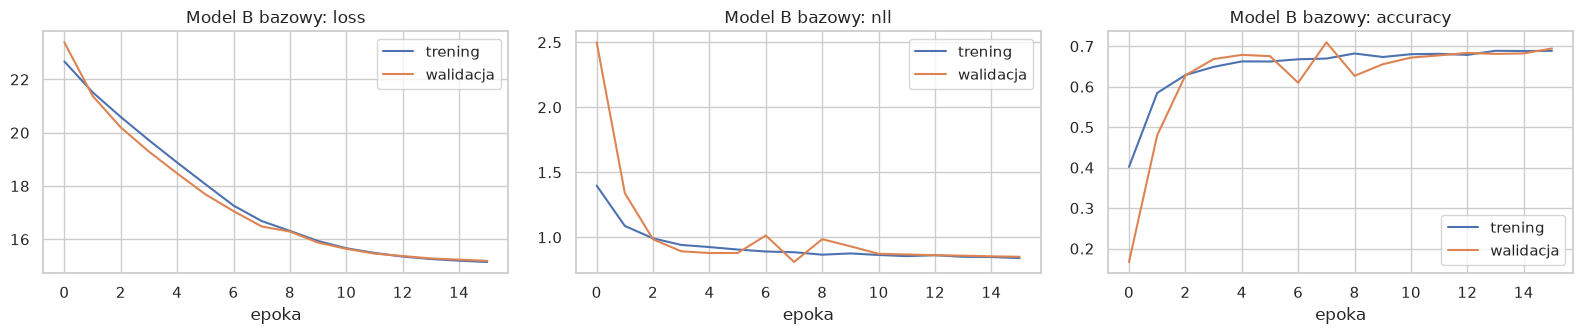

In [7]:
def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
    for key, ax in zip(["loss", "nll", "accuracy"], axes):
        ax.plot(history[key], label="trening")
        ax.plot(history[f"val_{key}"], label="walidacja")
        ax.set(title=f"{title} {key}", xlabel="epoka")
        ax.legend()
    plt.tight_layout()


plot_history(base_B.history, "Model B bazowy:")

W modelu B strata (`loss`) zawiera składnik KL, więc jest większa od `nll` i nie da się jej wprost porównać z modelem A.
Early stopping patrzy na walidacyjne `nll`, czyli na to samo, co w modelu A. Tak jak wcześniej liczy się kształt krzywych.

## 3. Ocena na walidacji i porównanie z modelem A

In [8]:
def timed_predict(run):
    """Próbki (T, N, K) na walidacji: T = 1 dla modelu A, mc_samples dla modelu B."""
    start = time.perf_counter()
    samples = predict_samples(run.model, data["val"]["X"], T=run.metrics["mc_samples"])
    return samples, time.perf_counter() - start


samples_A, t_A = timed_predict(run_A)
samples_B0, t_B0 = timed_predict(base_B)
probs_A, probs_B0 = samples_A.mean(axis=0), samples_B0.mean(axis=0)

pd.DataFrame({"model A": metrics(probs_A, y_val), "model B bazowy": metrics(probs_B0, y_val)}).round(3)

,model A,model B bazowy
accuracy,0.783,0.726
balanced_accuracy,0.689,0.694
macro_f1,0.694,0.648
nll,0.650,0.766
brier,0.329,0.396
ece,0.055,0.076
entropy,0.482,0.941


              precision    recall  f1-score   support

        NORM      0.869     0.773     0.818       916
          MI      0.570     0.543     0.556       234
        STTC      0.606     0.738     0.665       256
          CD      0.799     0.715     0.755       172
         HYP      0.326     0.703     0.446        64

    accuracy                          0.726      1642
   macro avg      0.634     0.694     0.648      1642
weighted avg      0.757     0.726     0.736      1642



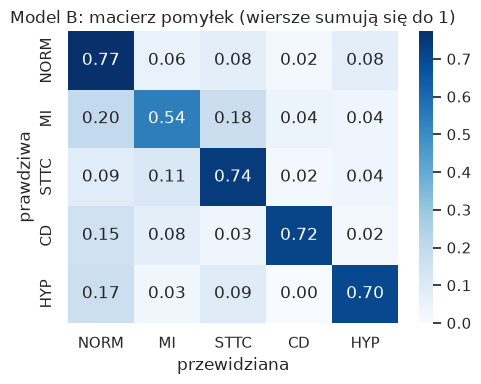

In [9]:
pred = probs_B0.argmax(axis=1)
print(classification_report(y_val, pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_val, pred, normalize="true")
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("przewidziana")
plt.ylabel("prawdziwa")
plt.title("Model B: macierz pomyłek (wiersze sumują się do 1)")
plt.tight_layout()

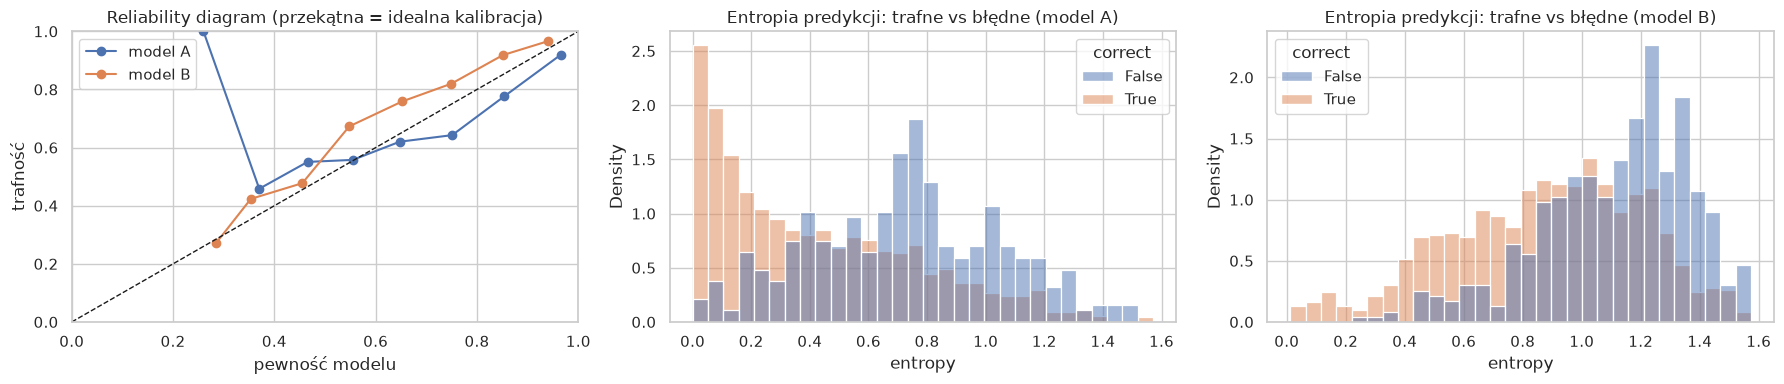

In [10]:
frame_A = predictions_frame(samples_A, data["val"])
frame_B0 = predictions_frame(samples_B0, data["val"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for probs, label in [(probs_A, "model A"), (probs_B0, "model B")]:
    table = reliability(probs, y_val)
    axes[0].plot(table["pewność"], table["trafność"], "o-", label=label)

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="pewność modelu", ylabel="trafność", xlim=(0, 1), ylim=(0, 1))
axes[0].set_title("Reliability diagram (przekątna = idealna kalibracja)")
axes[0].legend()

for ax, frame, name in [(axes[1], frame_A, "model A"), (axes[2], frame_B0, "model B")]:
    sns.histplot(data=frame, x="entropy", hue="correct", bins=30, stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Entropia predykcji: trafne vs błędne ({name})")

plt.tight_layout()

## 4. Dobór hiperparametrów

Architekturę, learning rate, dropout i wagi klas przejęliśmy z modelu A. Tu dobieramy tylko to, co specyficzne dla modelu B,
ponownie **jeden czynnik naraz** względem konfiguracji bazowej (4 treningi zamiast pełnej siatki):

| Czynnik | Warianty |
|---|---|
| waga składnika KL | 0,1, 0,3, 1 (bazowy) |
| dropout | 0, wartość z modelu A (bazowy) |

Składnik KL działa jak regularyzacja: zbyt silny powoduje niedouczenie, zbyt słaby sprawia, że rozkłady wag się zwężają
i model przestaje się różnić od deterministycznego. Dropout sprawdzamy dlatego, że warstwy Flipout same wprowadzają losowość,
więc może być on już zbędny.

**Kryterium wyboru: macro-F1 na walidacji**, tak samo jak w modelu A. NLL i ECE pokazujemy obok, żeby widzieć, jak wybór wpływa na kalibrację.

In [11]:
SEARCH = {
    "waga KL": {"bazowy": {}, "kl_01": {"kl_scale": 0.1}, "kl_03": {"kl_scale": 0.3}},
    "dropout": {"bazowy": {}, "dropout_0": {"dropout": 0.0}},
}

rows = []
for factor, variants in SEARCH.items():
    for name, changes in variants.items():
        r = run(name, **changes)
        rows.append({"czynnik": factor, "wariant": name, **r.metrics["val"], "epok": r.metrics["epochs"],
                     "minut": r.metrics["seconds"] / 60, "parametrów": r.metrics["parameters"], "run_id": r.run_id})

search = pd.DataFrame(rows).set_index(["czynnik", "wariant"])
search.round(3)

/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scal

accuracy  balanced_accuracy  macro_f1    nll  brier    ece  \
czynnik wariant                                                                 
waga KL bazowy        0.728              0.694     0.649  0.767  0.396  0.078   
        kl_01         0.745              0.718     0.669  0.693  0.360  0.044   
        kl_03         0.734              0.701     0.657  0.740  0.383  0.061   
dropout bazowy        0.728              0.694     0.649  0.767  0.396  0.078   
        dropout_0     0.728              0.694     0.649  0.767  0.396  0.078   

                   entropy  epok   minut  parametrów  \
czynnik wariant                                        
waga KL bazowy       0.941    16   9.537      224613   
        kl_01        0.811    27  15.908      224613   
        kl_03        0.885    16   9.497      224613   
dropout bazowy       0.941    16   9.537      224613   
        dropout_0    0.941    16   9.631      224613   

                                            run_id  
czynnik wariant                                     
waga KL bazowy        2026-11-24_22-13-06_B_bazowy  
        kl_01          2026-11-24_22-31-22_B_kl_01  
        kl_03          2026-11-24_22-42-11_B_kl_03  
dropout bazowy        2026-11-24_22-13-06_B_bazowy  
        dropout_0  2026-11-24_22-53-02_B_dropout_0

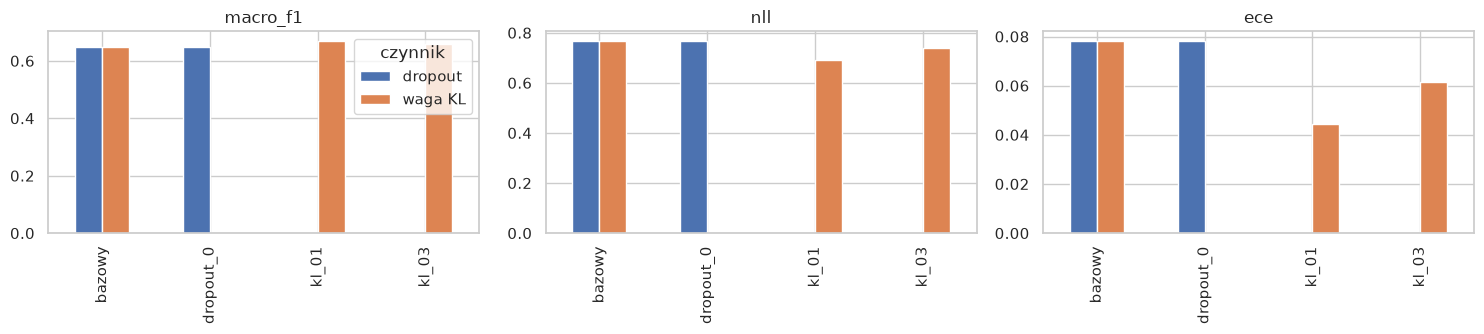

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, metric in zip(axes, ["macro_f1", "nll", "ece"]):
    search[metric].unstack(0).plot.bar(ax=ax, title=metric, legend=ax is axes[0])
    ax.set_xlabel("")
plt.tight_layout()

## 5. Wybrana konfiguracja i porównanie z modelem A

Dla każdego czynnika wybieramy wariant z najwyższym macro-F1 i łączymy wybory w jedną konfigurację.
Jeśli taka kombinacja nie była jeszcze trenowana, trenujemy ją teraz.

In [13]:
chosen = {}
for factor, variants in SEARCH.items():
    best = search.loc[factor, "macro_f1"].idxmax()
    print(f"{factor:15s} -> {best}")
    chosen.update(variants[best])

config_B = {**DEFAULT_CONFIG, **changes_A, **chosen}
pd.DataFrame({"model A": pd.Series({**DEFAULT_CONFIG, **changes_A}), "model B": pd.Series(config_B)})

waga KL         -> kl_01
dropout         -> bazowy


,model A,model B
filters,"(32, 64, 64, 128)","(32, 64, 64, 128)"
kernel_size,7,7
dense_units,64,64
dropout,0.3,0.3
learning_rate,0.001,0.001
batch_size,64,64
epochs,60,60
patience,8,8
class_weight_power,1.0,1.0
kl_scale,1.0,0.1


In [14]:
run_B = run("wybrany", **chosen)
print(f"Przebieg: {run_B.run_id}")
samples_B, t_B = timed_predict(run_B)
probs_B = samples_B.mean(axis=0)

summary = pd.DataFrame({
    "model A": pd.Series(run_A.metrics["val"]),
    "model B bazowy": pd.Series(base_B.metrics["val"]),
    "model B wybrany": pd.Series(run_B.metrics["val"]),
})
summary.round(3)

/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
/home/wojmichaluk/miniforge3/envs/prob-clf/lib/python3.11/site-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scal

Przebieg: 2026-11-24_22-31-22_B_kl_01


,model A,model B bazowy,model B wybrany
accuracy,0.783,0.728,0.745
balanced_accuracy,0.689,0.694,0.718
macro_f1,0.694,0.649,0.669
nll,0.650,0.767,0.693
brier,0.329,0.396,0.360
ece,0.055,0.078,0.044
entropy,0.482,0.941,0.811


              precision    recall  f1-score   support

        NORM      0.887     0.779     0.830       916
          MI      0.612     0.547     0.578       234
        STTC      0.610     0.789     0.688       256
          CD      0.776     0.785     0.780       172
         HYP      0.358     0.688     0.471        64

    accuracy                          0.745      1642
   macro avg      0.649     0.718     0.669      1642
weighted avg      0.772     0.745     0.753      1642



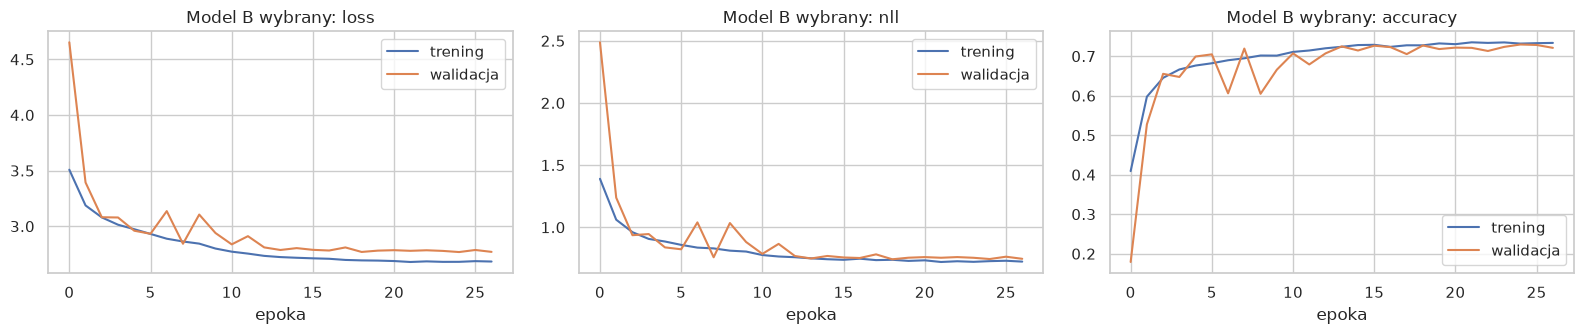

In [15]:
print(classification_report(y_val, probs_B.argmax(axis=1), target_names=CLASSES, digits=3))
plot_history(run_B.history, "Model B wybrany:")

### Koszt obliczeniowy

Model B ma więcej parametrów, trenuje się dłużej, a predykcja wymaga `mc_samples` przebiegów w przód zamiast jednego.

In [16]:
pd.DataFrame({
    "model A": {"parametrów": run_A.metrics["parameters"], "epok": run_A.metrics["epochs"],
                "czas treningu [min]": run_A.metrics["seconds"] / 60, "czas predykcji na walidacji [s]": t_A},
    "model B": {"parametrów": run_B.metrics["parameters"], "epok": run_B.metrics["epochs"],
                "czas treningu [min]": run_B.metrics["seconds"] / 60, "czas predykcji na walidacji [s]": t_B},
}).round(2)

,model A,model B
parametrów,113061.00,224613.00
epok,24.00,27.00
czas treningu [min],8.46,15.91
czas predykcji na walidacji [s],1.15,73.92


## 6. Niepewność aleatoryczna i epistemiczna

Całkowita entropia predykcji modelu B rozkłada się na dwie części:
**aleatoryczną** (średnia entropia pojedynczych próbek, niepewność związana z danymi) i **epistemiczną**
(mutual information, czyli to, jak bardzo kolejne próbki modelu się ze sobą nie zgadzają).
Model A ma tylko całkowitą entropię. Rozkład liczymy z `mc_samples` próbek zwróconych przez `predict_samples`.

In [17]:
def entropy(p):
    return -(p * np.log(np.clip(p, 1e-12, 1.0))).sum(axis=-1)


def decomposition(samples):
    """Rozkład entropii z próbek (T, N, K): całkowita = aleatoryczna + epistemiczna."""
    mean = samples.mean(axis=0)
    total = entropy(mean)
    aleatoric = entropy(samples).mean(axis=0)
    return {"probs": mean, "total": total, "aleatoric": aleatoric, "epistemic": total - aleatoric}


unc_B = decomposition(samples_B)
acc_check = (unc_B["probs"].argmax(axis=1) == y_val).mean()
print(f"Próbek na przykład: {samples_B.shape[0]}, accuracy: {acc_check:.3f} (w przebiegu: {run_B.metrics['val']['accuracy']:.3f})")

Próbek na przykład: 50, accuracy: 0.745 (w przebiegu: 0.745)


In [18]:
correct = unc_B["probs"].argmax(axis=1) == y_val
pd.DataFrame({
    "entropia całkowita": unc_B["total"],
    "entropia aleatoryczna": unc_B["aleatoric"],
    "entropia epistemiczna": unc_B["epistemic"],
}).groupby(np.where(correct, "trafne", "błędne")).mean().round(3)

,entropia całkowita,entropia aleatoryczna,entropia epistemiczna
błędne,1.028,0.948,0.08
trafne,0.736,0.686,0.05


### Zapowiedź głównej analizy: entropia a pewność diagnozy

Tak jak w notebooku 03, ale z obu modeli obok siebie, i tylko na walidacji. Pewność diagnozy nie była używana w treningu.
Pełne porównanie z przedziałami ufności zrobimy na zbiorze testowym.

In [19]:
frame_A = predictions_frame(samples_A, data["val"])
frame_B = predictions_frame(samples_B, data["val"])
assert len(frame_A) == len(frame_B) == len(unc_B["total"])

cmp = pd.DataFrame({
    "label": frame_B["label"].values,
    "likelihood": frame_B["likelihood"].values,
    "A: entropia": frame_A["entropy"].values,
    "B: entropia": unc_B["total"],
    "B: entropia aleatoryczna": unc_B["aleatoric"],
    "B: entropia epistemiczna": unc_B["epistemic"],
})
SCORES = ["A: entropia", "B: entropia", "B: entropia aleatoryczna", "B: entropia epistemiczna"]
subset = cmp[cmp.label.isin(["NORM", "MI"]) & cmp.likelihood.notna()]

(subset.groupby(["label", "likelihood"])[SCORES].mean().round(3)
       .join(subset.groupby(["label", "likelihood"]).size().rename("liczba")))

A: entropia  B: entropia  B: entropia aleatoryczna  \
label likelihood                                                       
MI    15.0              0.642        0.953                     0.879   
      35.0              0.720        0.993                     0.912   
      50.0              0.546        0.923                     0.853   
      80.0              0.612        0.836                     0.773   
      100.0             0.428        0.709                     0.646   
NORM  15.0              0.750        1.220                     1.151   
      35.0              0.676        1.012                     0.932   
      50.0              0.625        1.031                     0.961   
      80.0              0.556        0.919                     0.856   
      100.0             0.413        0.796                     0.743   

                  B: entropia epistemiczna  liczba  
label likelihood                                    
MI    15.0                           0.074      61  
      35.0                           0.082       8  
      50.0                           0.070      39  
      80.0                           0.063       8  
      100.0                          0.062     118  
NORM  15.0                           0.069       9  
      35.0                           0.079       4  
      50.0                           0.070      54  
      80.0                           0.064     153  
      100.0                          0.053     696

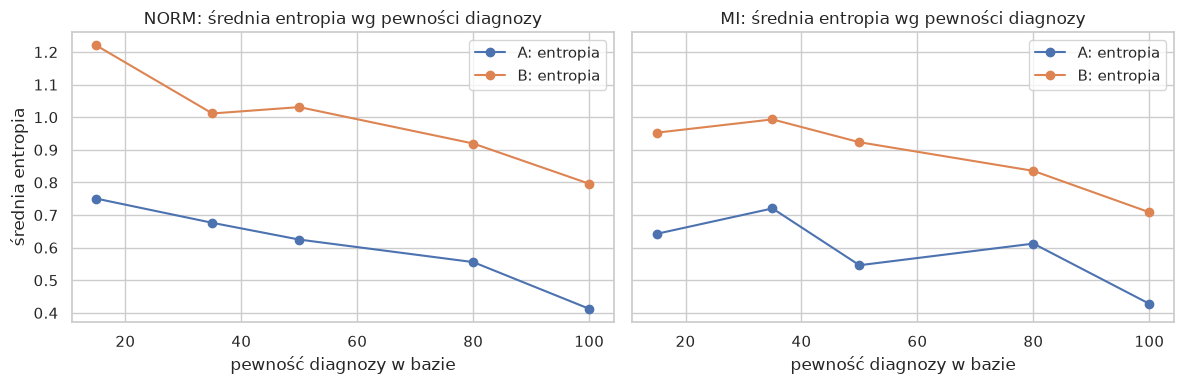

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, label in zip(axes, ["NORM", "MI"]):
    means = subset[subset.label == label].groupby("likelihood")[["A: entropia", "B: entropia"]].mean()
    means.plot(marker="o", ax=ax, title=f"{label}: średnia entropia wg pewności diagnozy")
    ax.set_xlabel("pewność diagnozy w bazie")
axes[0].set_ylabel("średnia entropia")
plt.tight_layout()

**AUROC rozróżnienia diagnoz niepewnych (pewność < 100) od pewnych (pewność 100)**, gdzie score to niepewność modelu (0,5 = model tego nie widzi).
Wartości **orientacyjne**: grupy na walidacji są małe, a przedziałów ufności jeszcze nie liczymy.

In [21]:
rows = []
for label in ["NORM", "MI"]:
    sub = subset[subset.label == label]
    uncertain = (sub.likelihood < 100).astype(int)
    for score in SCORES:
        rows.append({"klasa": label, "score": score, "AUROC": roc_auc_score(uncertain, sub[score]),
                     "niepewne / pewne": f"{uncertain.sum()} / {(1 - uncertain).sum()}"})
pd.DataFrame(rows).set_index(["klasa", "score"]).round(3)

AUROC niepewne / pewne
klasa score                                           
NORM  A: entropia               0.643        220 / 696
      B: entropia               0.645        220 / 696
      B: entropia aleatoryczna  0.644        220 / 696
      B: entropia epistemiczna  0.633        220 / 696
MI    A: entropia               0.656        116 / 118
      B: entropia               0.668        116 / 118
      B: entropia aleatoryczna  0.674        116 / 118
      B: entropia epistemiczna  0.586        116 / 118

In [22]:
# Wybrana konfiguracja modelu B na potrzeby testu
(RESULTS / "config_B.json").write_text(json.dumps(
    {"run_id": run_B.run_id, "config": config_B, "model_A_run_id": run_A.run_id}, indent=2, default=str))
print("Zapisano results/config_B.json")

Zapisano results/config_B.json


### Wszystkie przebiegi

Ta sama tabela jest w `runs/index.csv`, a w terminalu: `python -m src.runs`.

In [23]:
list_runs()[["model", "val_accuracy", "val_macro_f1", "val_nll", "val_ece", "epochs", "minutes", "commit"]]

,model,val_accuracy,val_macro_f1,val_nll,val_ece,epochs,minutes,commit
run_id,,,,,,,,
2026-11-22_22-10-32_A_bazowy,A,0.7832,0.6943,0.6500,0.0551,24,8.46,37412f4
2026-11-22_22-17-29_A_wagi_brak,A,0.7868,0.6775,0.5993,0.0501,18,6.83,37412f4
2026-11-22_22-24-21_A_wagi_lagodne,A,0.7893,0.6914,0.6033,0.0465,18,6.83,37412f4
2026-11-22_22-34-03_A_dropout_0,A,0.7728,0.6912,0.6462,0.0301,18,9.65,37412f4
2026-11-22_22-45-52_A_dropout_05,A,0.7832,0.6689,0.6421,0.0658,24,11.76,37412f4
2026-11-22_22-49-04_A_siec_mala,A,0.7600,0.6639,0.6995,0.0388,13,3.15,37412f4
2026-11-22_23-29-35_A_siec_duza,A,0.7625,0.6746,0.6589,0.0633,24,40.43,37412f4
2026-11-24_22-13-06_B_bazowy,B,0.7284,0.6492,0.7673,0.0782,16,9.54,37412f4
2026-11-24_22-31-22_B_kl_01,B,0.7448,0.6694,0.6926,0.0443,27,15.91,37412f4


## 7. Wnioski

Wnioski dotyczą zbioru walidacyjnego i jednego seeda (0), więc są wstępne. Wybrana konfiguracja modelu B to konfiguracja modelu A z `kl_scale = 0,1`.

**Jakość klasyfikacji.** Model B jest nieco słabszy od A: accuracy 0,745 wobec 0,783 i macro-F1 0,669 wobec 0,694. Balanced accuracy jest za to wyższa w B (0,718 wobec 0,689), bo B lepiej rozpoznaje klasy mniejszościowe (recall HYP 0,69, CD 0,79, STTC 0,79). Wszystkie trzy warianty B mają niższą accuracy niż każdy wariant A, więc ta różnica prawdopodobnie jest rzeczywista, choć trzeba ją potwierdzić na kilku seedach.

**Kalibracja i pewność predykcji.** NLL i Brier są lepsze w modelu A (0,650 i 0,329 wobec 0,693 i 0,360). ECE jest minimalnie lepsze w B (0,044 wobec 0,055), ale taka różnica przy jednym seedzie nie pozwala niczego rozstrzygnąć. Średnia entropia predykcji B jest wyraźnie wyższa (0,81 wobec 0,48), czyli B jest ogólnie mniej pewny siebie. Na tym etapie nie widać więc przewagi B w kalibracji, co zgadza się z oczekiwaniem z README dla dużego zbioru i czystych danych.

**Wpływ składnika KL.** Im słabszy składnik KL, tym lepiej: przy `kl_scale` = 1, 0,3, 0,1 macro-F1 rośnie (0,649, 0,657, 0,669), a NLL (0,767, 0,740, 0,693) i ECE (0,078, 0,061, 0,044) maleją. Pełna waga KL niedouczała model (16 epok, a przy 0,1 trening trwał 27). Najlepszy wariant jest zarazem najmniejszym sprawdzonym, więc optimum może leżeć poniżej 0,1.

**Dropout.** Wariant `dropout_0` dał wyniki identyczne z bazowym, więc w modelu B parametr `dropout` nie ma wpływu (w architekturze nie ma warstwy Dropout). Model B ma więc w praktyce inną regularyzację niż A: Flipout i KL zamiast dropoutu.

**Niepewność a pewność diagnozy.** Entropia obu modeli maleje, gdy rośnie pewność diagnozy w bazie. AUROC rozróżnienia diagnoz niepewnych od pewnych jest prawie taki sam w obu modelach (NORM 0,643 i 0,645, MI 0,656 i 0,668). Przy grupach 116 i 118 (MI) różnice rzędu 0,01 mieszczą się w błędzie, więc model B nie widzi wątpliwości lekarza lepiej niż A.

**Niepewność aleatoryczna i epistemiczna.** Niepewność modelu B to w ok. 92-93% część aleatoryczna, a epistemiczna stanowi tylko ok. 7-8% całkowitej entropii (0,05-0,08). Kierunek jest właściwy: epistemiczna jest wyższa dla błędnych predykcji (0,080 wobec 0,050) i dla mniej pewnych diagnoz. Jako sygnał niepewności diagnozy działa jednak słabiej niż część aleatoryczna (AUROC 0,633 dla NORM i 0,586 dla MI wobec 0,644 i 0,674). Zmniejszanie `kl_scale` poprawia metryki, ale zawęża rozkłady wag, a więc ogranicza część epistemiczną.

**Koszt.** Model B ma 2 razy więcej parametrów (224 613 wobec 113 061) i trenuje się znacznie dłużej (15,9 wobec 8,5 min). Predykcja na walidacji wymaga 50 przebiegów i trwa 74 s wobec 1,15 s w modelu A (ok. 64 razy dłużej).

**Co dalej.** Przed testem trzeba: (1) rozszerzyć siatkę `kl_scale` poniżej 0,1, (2) powtórzyć A i B dla kilku seedów, (3) porównać B także z modelem A bez dropoutu (`A_dropout_0`, ECE 0,030), bo B dropoutu nie ma. Główną przewagę modelu B przewidujemy przy małym zbiorze i szumie, czego tu jeszcze nie badaliśmy.